## Status: frozen on 11 Nov 2026

Work on this notebook has stopped. Sections 10-20 are not to be tuned further on daily ETF returns.

- CRP geometry fill (sections 10-15): for IWM the GARCH-standardised version is worse than predict-zero (MAE 0.0110 against 0.0093) and its best variant, raw states, reaches 0.0089. The vol-scaled SPY regression has 0.0042 on the same 49 points.
- CRP-analog residual correction (sections 16-20): equal to the SPY regression, MAE 0.00963 against 0.00950 over 13 products and 938 points.
- Section 21 gives the reason. With 5 days of context on each side, neither ridge nor gradient boosting predicts the residual of the same-day SPY regression out of sample (mean R² gain -0.009 and +0.003 on 2022-2024). The same-day returns of the other products add +0.171. On daily returns the information that the regression misses is cross-sectional, not temporal.

Known limits of sections 9-20, left as they are:

- Scores are inside the train period only (2015-2021). K and shrink were tuned on pseudo-missing days of the same period.
- The donor libraries of sections 10 and 13 are built from the ground-truth series (`z_ground_train`, `mode_data["ground"]`), which contain the removed values.
- Baselines are scored only on the points the CRP solver could fill (49 of 76 for IWM).

## Idea

I want to asses how usable are RPs for the construction of missing data for a day's movement given the RP of a product that has very high correlation with this one, and that has those days available.

Can allow us to model how the system looked or would have looked, had there been a day of no records.

Only reason for this to make sense is that even tho Recurrence plots carry the same information as the raw series, the matrix of distances and RQAs from a highly correlated product that is not the same, together with a study of how the 2 move together can allow for superior modelling of the missing data.

Simple steps 
- get a series that has gaps (holidays, market closes etc) 
- find correlated series that has those specific gaps fixed. Can be determined by using simple correlation and furhter RQA for more precise dynamical analysis.
- Reconstruct the series using different methods for data reconstruction. Direct imputation, use of the correlated series' movement in some way, or a RQA based reconstruction from the other known dataset.
- Compare different construction methods

## 1. Fetch products

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

# The 14 products of 06_torp (equity indices / sectors, gold, silver,
# natural gas, bonds, yen, VIX). Each series keeps its own calendar below.
TICKERS = ["SPY", "IWM", "EFA", "EWZ", "FXI", "XLE", "XLP",
           "GLD", "SLV", "UNG", "TIP", "HYG", "FXY", "^VIX"]
PRODUCTS = list(TICKERS)
START, END = "2015-01-01", "2025-01-01"
PRICES = Path("../../data/raw/yahoo/missing_data_torp_products_2015_2024.csv")

if PRICES.exists():
    prices = pd.read_csv(PRICES, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    prices = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)["Close"]
    prices = prices[TICKERS]
    PRICES.parent.mkdir(parents=True, exist_ok=True)
    prices.to_csv(PRICES)

# One daily log-return series per ticker, on that ticker's own dates
returns = {t: np.log(prices[t].dropna()).diff().dropna() for t in TICKERS}
for t, r in returns.items():
    print(f"{t}: {len(r)} daily log returns, {r.index[0].date()} to {r.index[-1].date()}")

SPY: 2515 daily log returns, 2015-01-05 to 2024-12-31
IWM: 2515 daily log returns, 2015-01-05 to 2024-12-31
EFA: 2515 daily log returns, 2015-01-05 to 2024-12-31
EWZ: 2515 daily log returns, 2015-01-05 to 2024-12-31
FXI: 2515 daily log returns, 2015-01-05 to 2024-12-31
XLE: 2515 daily log returns, 2015-01-05 to 2024-12-31
XLP: 2515 daily log returns, 2015-01-05 to 2024-12-31
GLD: 2515 daily log returns, 2015-01-05 to 2024-12-31
SLV: 2515 daily log returns, 2015-01-05 to 2024-12-31
UNG: 2515 daily log returns, 2015-01-05 to 2024-12-31
TIP: 2515 daily log returns, 2015-01-05 to 2024-12-31
HYG: 2515 daily log returns, 2015-01-05 to 2024-12-31
FXY: 2515 daily log returns, 2015-01-05 to 2024-12-31
^VIX: 2515 daily log returns, 2015-01-05 to 2024-12-31


## 2. Remove a random 3-5% of days from every product except SPY

In [2]:
# Each product except SPY loses its own random 3-5% of days (a different
# percentage and different days per product; fixed seed, so reruns agree).
# `returns` stays intact as the ground truth; the removed values are kept
# in removed_days[t] for later scoring of any reconstruction.
rng = np.random.default_rng(42)
masked_returns = {}
removed_days = {}
mask_rows = []
for t, r in returns.items():
    if t == "SPY":
        masked_returns[t] = r.copy()
        removed_days[t] = r.iloc[0:0]
        mask_rows.append({"ticker": t, "n": len(r), "removed_n": 0,
                          "removed_pct": 0.0, "remaining_n": len(r)})
        continue
    frac = rng.uniform(0.03, 0.05)
    n_remove = int(round(frac * len(r)))
    positions = rng.choice(len(r), size=n_remove, replace=False)
    removed = r.iloc[np.sort(positions)].sort_index()
    removed_days[t] = removed
    masked_returns[t] = r.drop(removed.index)
    mask_rows.append({"ticker": t, "n": len(r), "removed_n": n_remove,
                      "removed_pct": 100.0 * n_remove / len(r),
                      "remaining_n": len(masked_returns[t])})
    assert 3.0 <= 100.0 * n_remove / len(r) <= 5.0
assert masked_returns["SPY"].equals(returns["SPY"])
mask_summary = pd.DataFrame(mask_rows).set_index("ticker")
mask_summary

,n,removed_n,removed_pct,remaining_n
ticker,,,,
SPY,2515,0,0.000000,2515
IWM,2515,114,4.532803,2401
EFA,2515,119,4.731610,2396
EWZ,2515,122,4.850895,2393
FXI,2515,116,4.612326,2399
XLE,2515,82,3.260437,2433
XLP,2515,90,3.578529,2425
GLD,2515,76,3.021869,2439
SLV,2515,124,4.930417,2391


## 3. Split each series 70/30 in time

In [3]:
# Chronological 70/30 split of each series separately (no shuffling,
# and each split is cut on the series' own calendar).
splits = {}
rows = []
for t, r in masked_returns.items():
    cut = int(0.70 * len(r))
    train, test = r.iloc[:cut], r.iloc[cut:]
    assert len(train) + len(test) == len(r) and train.index[-1] < test.index[0]
    splits[t] = {"train": train, "test": test}
    rows.append({"ticker": t, "n": len(r), "train_n": len(train), "test_n": len(test),
                 "train": f"{train.index[0].date()} to {train.index[-1].date()}",
                 "test": f"{test.index[0].date()} to {test.index[-1].date()}"})
split_summary = pd.DataFrame(rows).set_index("ticker")
split_summary

,n,train_n,test_n,train,test
ticker,,,,,
SPY,2515,1760,755,2015-01-05 to 2021-12-29,2021-12-30 to 2024-12-31
IWM,2401,1680,721,2015-01-05 to 2021-12-22,2021-12-23 to 2024-12-31
EFA,2396,1677,719,2015-01-05 to 2022-01-07,2022-01-10 to 2024-12-31
EWZ,2393,1675,718,2015-01-05 to 2021-12-20,2021-12-21 to 2024-12-31
FXI,2399,1679,720,2015-01-05 to 2021-12-20,2021-12-21 to 2024-12-31
XLE,2433,1703,730,2015-01-05 to 2022-01-05,2022-01-06 to 2024-12-31
XLP,2425,1697,728,2015-01-05 to 2022-01-03,2022-01-04 to 2024-12-30
GLD,2439,1707,732,2015-01-05 to 2022-01-03,2022-01-04 to 2024-12-31
SLV,2391,1673,718,2015-01-05 to 2022-01-04,2022-01-05 to 2024-12-31


## 4. Correlation of each product with SPY on its remaining days

In [4]:
# Pearson correlation of daily log returns with SPY, computed separately
# for each product on that product's remaining days only (the days left in
# masked_returns after the random removal). SPY itself lost no days.
spy_returns = masked_returns["SPY"]
corr_rows = []
for ticker in PRODUCTS:
    if ticker == "SPY":
        continue
    pair = pd.concat([masked_returns[ticker].rename(ticker), spy_returns.rename("SPY")], axis=1, join="inner").dropna()
    corr_rows.append({"product": ticker, "corr_with_spy": pair[ticker].corr(pair["SPY"]), "n_days": len(pair)})

corr_with_spy = (pd.DataFrame(corr_rows).set_index("product").sort_values("corr_with_spy", ascending=False))
corr_with_spy = corr_with_spy[corr_with_spy["corr_with_spy"] >= 0.7]
corr_with_spy

,corr_with_spy,n_days
product,,
IWM,0.869522,2401
EFA,0.854212,2396
HYG,0.772074,2412
XLP,0.727605,2425


## 5. Recurrence plots on the last 70 days: SPY x IWM and SPY x SPY

In [5]:
import sys

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.embedding import embed
from recplay.recurrence import euclidean_distances, threshold_by_rate
from recplay.torp import cross_distances

M, TAU, RR = 3, 1, 0.45
WINDOW = 65

# Last 70 days SPY and IWM have in common (IWM lost some days in section 2);
# the SPY-only plot uses the same 70 dates, so the two plots are comparable.
pair = (pd.concat([masked_returns["SPY"].rename("SPY"),
                   masked_returns["IWM"].rename("IWM")], axis=1, join="inner")
        .dropna().iloc[-WINDOW:])

def embedded(series):
    z = (series - series.mean()) / series.std()
    return embed(z.to_numpy(dtype=float), M, TAU)

states_spy = embedded(pair["SPY"])
states_iwm = embedded(pair["IWM"])
state_dates = pair.index[(M - 1) * TAU:]

# Cross-recurrence SPY x IWM: state of SPY at i close to state of IWM at j.
D_spy_iwm = cross_distances(states_spy, states_iwm)
eps_spy_iwm = float(np.quantile(D_spy_iwm, RR))
R_spy_iwm = D_spy_iwm <= eps_spy_iwm

# Self-recurrence SPY x SPY.
D_spy = euclidean_distances(states_spy)
R_spy = threshold_by_rate(D_spy, RR)

# Distance profiles
profile_spy_iwm = D_spy_iwm
profile_spy = D_spy

# Multiple threshold levels
LEVELS = np.array(sorted({0.05, 0.10, 0.20, 0.30, float(RR)}))
eps_levels_spy_iwm = np.quantile(D_spy_iwm, LEVELS)
eps_levels_spy = np.quantile(D_spy[np.triu_indices(len(D_spy), k=1)], LEVELS)
level_spy_iwm = np.digitize(D_spy_iwm, eps_levels_spy_iwm)
level_spy = np.digitize(D_spy, eps_levels_spy)

print(f"window: {pair.index[0].date()} to {pair.index[-1].date()} "f"({len(pair)} days, {len(states_spy)} embedded states)")
print(f"SPY x IWM: shape {R_spy_iwm.shape}, eps {eps_spy_iwm:.3f}, recurrence rate {R_spy_iwm.mean():.3f}")
print(f"SPY x SPY: shape {R_spy.shape}, recurrence rate {R_spy.mean():.3f}")
print(f"threshold levels {LEVELS}; SPY x IWM eps {np.round(eps_levels_spy_iwm, 3)}; "f"SPY x SPY eps {np.round(eps_levels_spy, 3)}")

window: 2024-09-27 to 2024-12-31 (65 days, 63 embedded states)
SPY x IWM: shape (63, 63), eps 1.770, recurrence rate 0.450
SPY x SPY: shape (63, 63), recurrence rate 0.443
threshold levels [0.05 0.1  0.2  0.3  0.45]; SPY x IWM eps [0.711 0.907 1.222 1.44  1.77 ]; SPY x SPY eps [0.665 0.888 1.174 1.437 1.788]


## 6. Plot the two recurrence plots

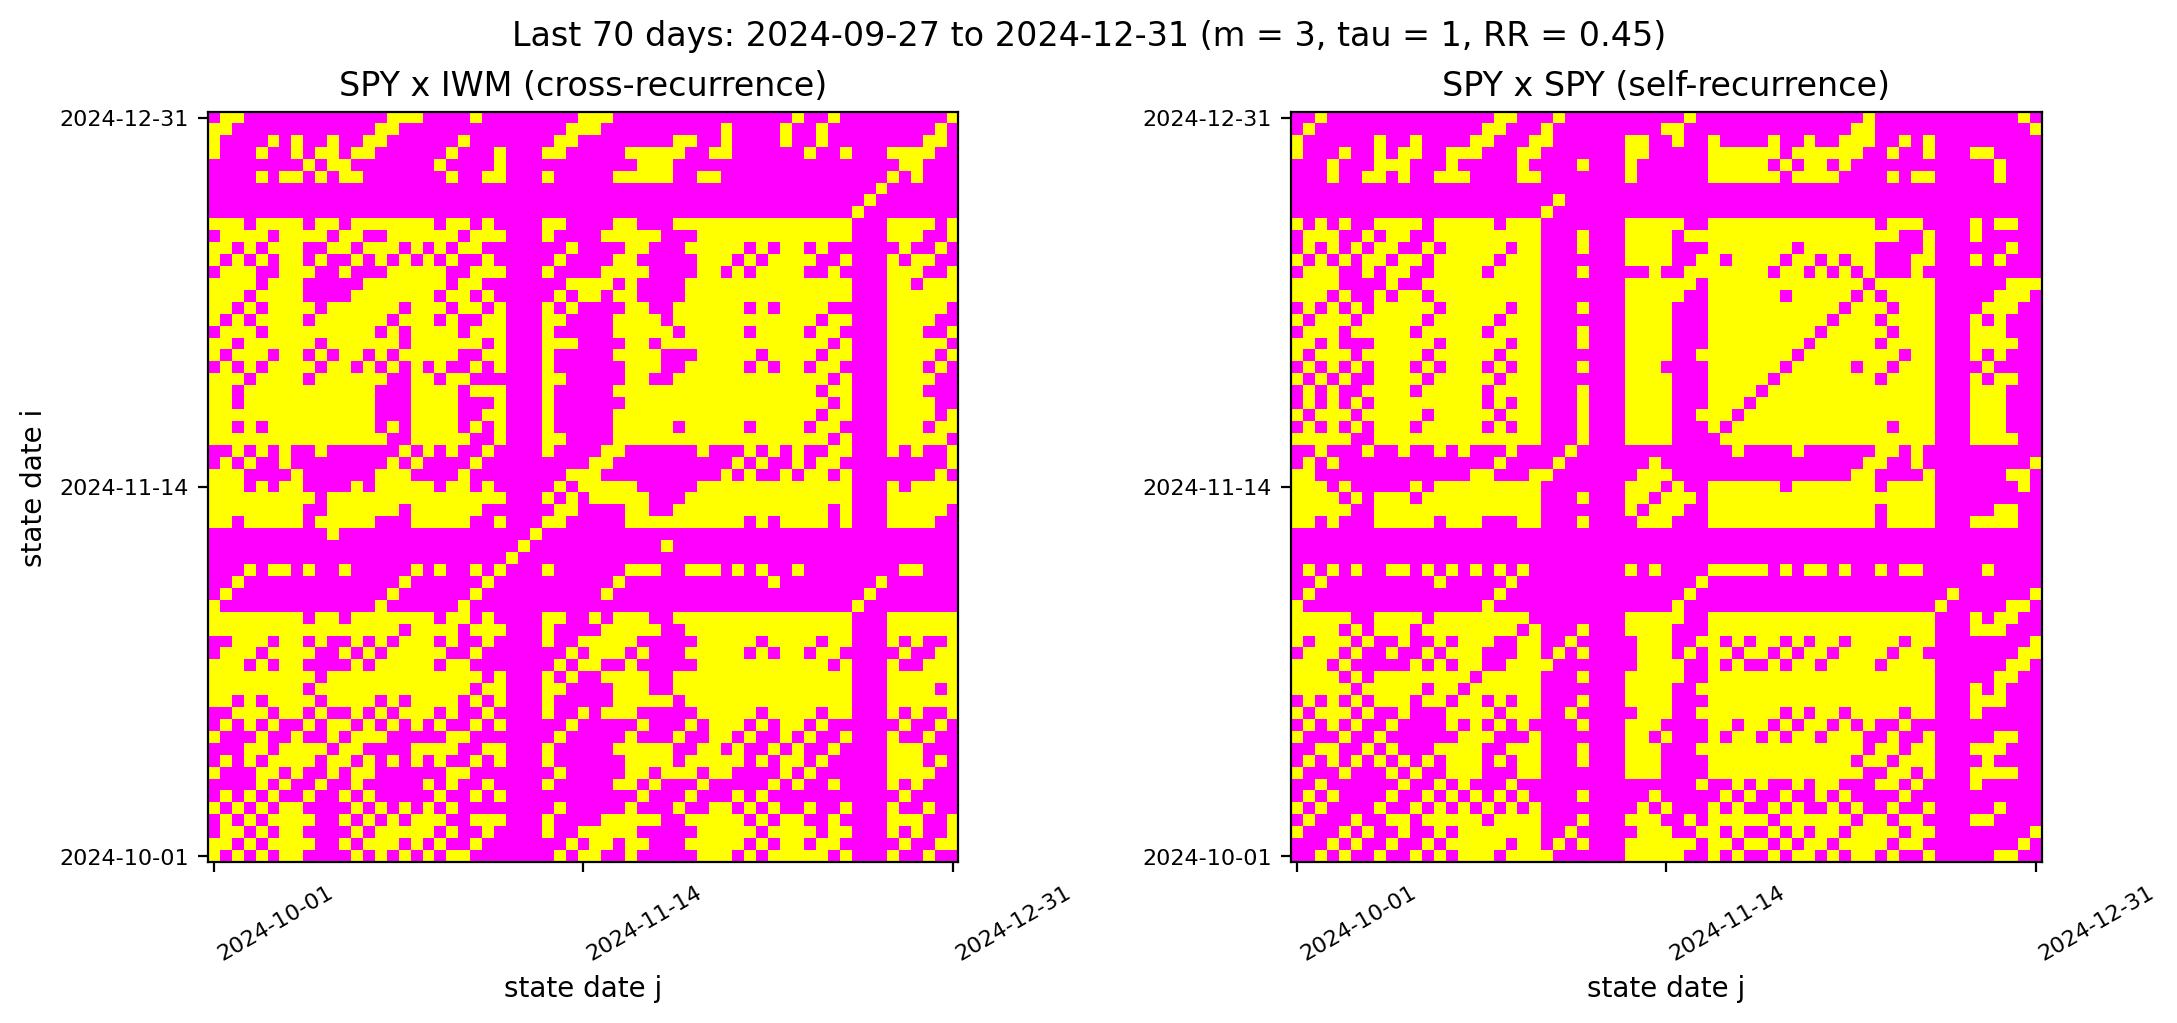

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(ncols=2, figsize=(11, 5), layout="constrained")
tick_pos = [0, len(state_dates) // 2, len(state_dates) - 1]
tick_labels = [state_dates[i].strftime("%Y-%m-%d") for i in tick_pos]
for ax, R, title in [(axes[0], R_spy_iwm, "SPY x IWM (cross-recurrence)"),
                     (axes[1], R_spy, "SPY x SPY (self-recurrence)")]:
    ax.imshow(R, origin="lower", cmap="spring", interpolation="nearest")
    ax.set_xticks(tick_pos, tick_labels, rotation=30, ha="left", fontsize=8)
    ax.set_yticks(tick_pos, tick_labels, fontsize=8)
    ax.set_xlabel("state date j")
    ax.set_title(title)
axes[0].set_ylabel("state date i")
fig.suptitle(f"Last 70 days: {pair.index[0].date()} to {pair.index[-1].date()} "
             f"(m = {M}, tau = {TAU}, RR = {RR})")
plt.show()

## Precise setting of experiment

### Let 2 systems X,Y, with known Correlation, and data of system X is more full compared to data of system Y. 

### Use the following to make an approximation of Y system's missing values :
    Y's RP before the gap, SPY's RP before the gap and SPY's RP on the gap.
    

2 different tasks to try this on :
    
    - Causal ~ Use only past information - forecasting style fill, so harder.
    - two sided ~ more reasonable, direct comparison to methods like interpolation.

## 7. Same plots coloured by threshold level

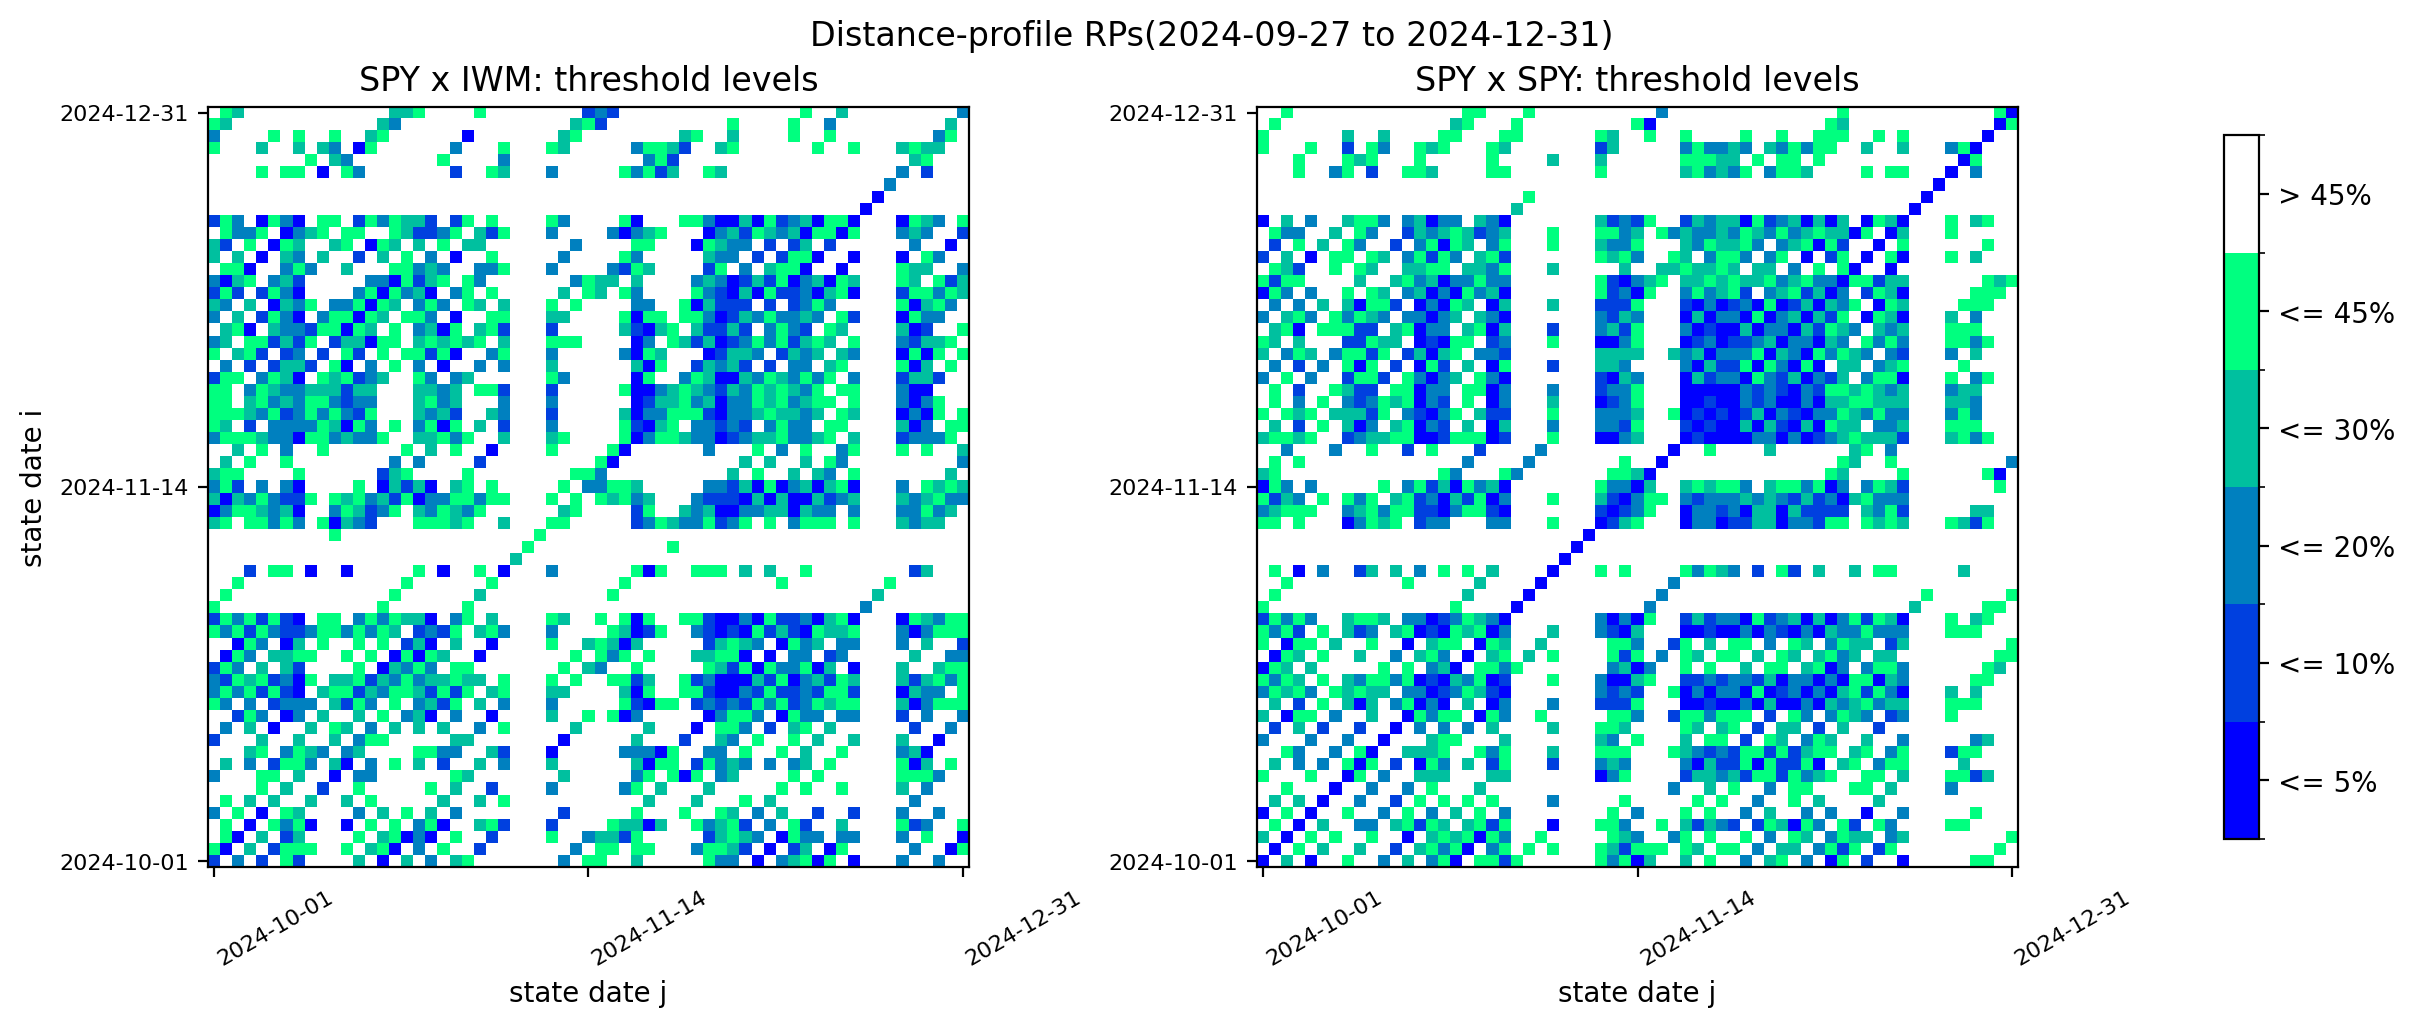

In [7]:
# Colour = the loosest threshold level at which the pair becomes recurrent
# (dark = recurrent already at the tightest level, i.e. smallest distance;
# white = not recurrent even at the loosest level). This keeps the distance
# profile information that the binary RPs of section 6 throw away.
import matplotlib as mpl

n_levels = len(LEVELS)
level_colors = [plt.cm.winter(k / max(n_levels - 1, 1)) for k in range(n_levels)] + ["white"]
cmap_levels = mpl.colors.ListedColormap(level_colors)
norm_levels = mpl.colors.BoundaryNorm(np.arange(-0.5, n_levels + 1.5), cmap_levels.N)

fig2, axes2 = plt.subplots(ncols=2, figsize=(12, 5), layout="constrained")
for ax, L, title in [(axes2[0], level_spy_iwm, "SPY x IWM: threshold levels"),(axes2[1], level_spy, "SPY x SPY: threshold levels")]:
    im = ax.imshow(L, origin="lower", cmap=cmap_levels, norm=norm_levels,interpolation="nearest")
    ax.set_xticks(tick_pos, tick_labels, rotation=30, ha="left", fontsize=8)
    ax.set_yticks(tick_pos, tick_labels, fontsize=8)
    ax.set_xlabel("state date j")
    ax.set_title(title)
    
axes2[0].set_ylabel("state date i")
cbar = fig2.colorbar(im, ax=axes2, ticks=list(range(n_levels + 1)), shrink=0.9)
cbar.ax.set_yticklabels([f"<= {100 * q:.0f}%" for q in LEVELS] + [f"> {100 * LEVELS[-1]:.0f}%"])
fig2.suptitle(f"Distance-profile RPs"f"({pair.index[0].date()} to {pair.index[-1].date()})")
plt.show()

## 8. GARCH volatilities for SPY and IWM

In [8]:
# MLE GARCH(1,1) with Student-t innovations, fitted per system on the train
# split of the masked series only (never on removed values). Parameters are
# then frozen and the sigma recursion is filtered over the full masked
# series, so sigma exists on every non-missing day; for a missing day the
# one-step-ahead forecast from the last observed day is used.
from scipy.optimize import minimize
from scipy.special import gammaln

TARGET, HELPER = "IWM", "SPY"
EMB_M, EMB_TAU, RP_RR, CONTEXT_W = 3, 1, 0.10, 65

def _garch_sigma2(eps_pct, omega, alpha, beta):
    sig2 = np.empty(len(eps_pct))
    sig2[0] = np.var(eps_pct)
    for i in range(1, len(eps_pct)):
        sig2[i] = omega + alpha * eps_pct[i - 1] ** 2 + beta * sig2[i - 1]
    return sig2

def fit_garch11_t(train_returns):
    eps = train_returns.to_numpy(dtype=float) * 100.0
    def nll(p):
        omega, alpha, beta, nu = p
        if alpha + beta >= 0.999:
            return 1e12
        sig2 = _garch_sigma2(eps, omega, alpha, beta)
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2)
              - 0.5 * np.log(np.pi * (nu - 2) * sig2)
              - ((nu + 1) / 2) * np.log1p(eps ** 2 / ((nu - 2) * sig2)))
        return -float(ll.sum())
    res = minimize(nll, x0=[0.02, 0.08, 0.90, 8.0], method="L-BFGS-B",
                   bounds=[(1e-8, None), (0.0, 0.999), (0.0, 0.999), (2.1, 100.0)])
    omega, alpha, beta, nu = [float(v) for v in res.x]
    return {"omega": omega, "alpha": alpha, "beta": beta, "nu": nu}

def garch_filter_pct(series, params):
    eps = series.to_numpy(dtype=float) * 100.0
    sig2 = _garch_sigma2(eps, params["omega"], params["alpha"], params["beta"])
    return pd.Series(np.sqrt(sig2), index=series.index)

garch_params, sigma_pct, sigma = {}, {}, {}
for ticker in [HELPER, TARGET]:
    garch_params[ticker] = fit_garch11_t(masked_returns[ticker].loc[splits[ticker]["train"].index])
    sigma_pct[ticker] = garch_filter_pct(masked_returns[ticker], garch_params[ticker])
    sigma[ticker] = sigma_pct[ticker] / 100.0
    print(ticker, {k: round(v, 4) for k, v in garch_params[ticker].items()})

def iwm_sigma_at(date):
    if date in sigma[TARGET].index:
        return float(sigma[TARGET].loc[date])
    prev_pos = sigma[TARGET].index.searchsorted(date) - 1
    p = garch_params[TARGET]
    eps_prev = float(masked_returns[TARGET].iloc[prev_pos]) * 100.0
    sig_prev = float(sigma_pct[TARGET].iloc[prev_pos])
    return float(np.sqrt(p["omega"] + p["alpha"] * eps_prev ** 2 + p["beta"] * sig_prev ** 2)) / 100.0

SPY {'omega': 0.0211, 'alpha': 0.2121, 'beta': 0.7868, 'nu': 5.8779}
IWM {'omega': 0.0369, 'alpha': 0.1188, 'beta': 0.8612, 'nu': 7.9996}


## 9. Train-only setup for CRP filling (SPY helps IWM)

In [9]:
# Everything in sections 9-11 stays inside the train period: series are
# clipped to TRAIN_DATES, GARCH is fitted on masked train data only, and
# ground-truth train returns are used only for the donor library and for
# scoring. The test split is never read here.
TARGETS = [TARGET]
TRAIN_DATES = splits[HELPER]["train"].index
TRAIN_END = TRAIN_DATES.max()

garch_params_all = dict(garch_params)
sigma_train = {t: sigma[t].loc[splits[t]["train"].index] for t in [HELPER, TARGET]}
for ticker in TARGETS:
    if ticker in sigma_train:
        continue
    masked_train = splits[ticker]["train"]
    garch_params_all[ticker] = fit_garch11_t(masked_train)
    sigma_train[ticker] = garch_filter_pct(masked_train, garch_params_all[ticker]) / 100.0

sigma_cal, z_ground_train, z_masked_train = {}, {}, {}
for ticker in [HELPER, TARGET]:
    sigma_cal[ticker] = sigma_train[ticker].reindex(TRAIN_DATES).ffill().bfill()
    z_ground_train[ticker] = returns[ticker].loc[TRAIN_DATES] / sigma_cal[ticker]
    z_masked_train[ticker] = masked_returns[ticker].reindex(TRAIN_DATES) / sigma_cal[ticker]

spy_z = z_ground_train[HELPER].to_numpy(dtype=float)
spy_states_all = embed(spy_z, EMB_M, EMB_TAU)  # row i is the state ending at TRAIN_DATES[i + 2]
print(f"train period: {TRAIN_DATES.min().date()} to {TRAIN_END.date()} ({len(TRAIN_DATES)} days)")

train period: 2015-01-05 to 2021-12-29 (1760 days)


## 10. Donor CRP profiles and the optimisation for a

In [10]:
# For a missing day t of a product Y, the three Y states containing the
# unknown standardised return a are the states ending t, t+1, t+2 (a sits
# in coordinate 3, 2, 1 respectively). Target cross-distances d_hat come
# from donor days: observed train days of Y whose SPY/Y context around the
# day resembles this day's context, aligned by relative position, weighted
# by resemblance. a is then the one-dimensional minimiser of
# sum w * (||S_i(a) - S_spy_j|| - d_hat_ij)^2 over those three states and
# the SPY states in a window around t.
from scipy.optimize import minimize_scalar

CRP_HALF, CONTEXT_L, K_DONORS = 32, 5, 25

def context_descriptor(center_pos, y_context):
    if center_pos - CONTEXT_L < 0 or center_pos + CONTEXT_L >= len(y_context):
        return None
    offsets = [o for o in range(-CONTEXT_L, CONTEXT_L + 1) if o != 0]
    desc = np.concatenate([spy_z[center_pos - CONTEXT_L:center_pos + CONTEXT_L + 1],
                           y_context[[center_pos + o for o in offsets]]])
    return desc if np.isfinite(desc).all() else None

def donor_library(product):
    y_ground = z_ground_train[product].to_numpy(dtype=float)
    y_states = embed(y_ground, EMB_M, EMB_TAU)
    observed = set(masked_returns[product].index)
    centers, descs = [], []
    for q in range(CRP_HALF, len(TRAIN_DATES) - CRP_HALF - 2):
        if TRAIN_DATES[q] not in observed:
            continue
        desc = context_descriptor(q, y_ground)
        if desc is not None:
            centers.append(q)
            descs.append(desc)
    return {"centers": np.array(centers), "descs": np.vstack(descs),
            "y_states": y_states}

def _profile_for_center(q, y_states):
    spy_rows = [e - (EMB_M - 1) for e in range(q - CRP_HALF, q + CRP_HALF + 1)]
    spy_states = spy_states_all[spy_rows]
    rows = []
    for end_offset in [0, 1, 2]:
        y_state = y_states[q + end_offset - (EMB_M - 1)]
        rows.append(cross_distances(y_state[None, :], spy_states)[0])
    return np.vstack(rows)

def target_profile(t_pos, product, library):
    desc = context_descriptor(t_pos, z_masked_train[product].to_numpy(dtype=float))
    if desc is None:
        return None
    dists = np.linalg.norm(library["descs"] - desc, axis=1)
    nearest = np.argsort(dists)[:K_DONORS]
    donor_pos = library["centers"][nearest]
    scale = max(float(np.median(dists[nearest])), 1e-9)
    weights = np.exp(-0.5 * (dists[nearest] / scale) ** 2)
    weights = weights / weights.sum()
    profiles = np.stack([_profile_for_center(int(q), library["y_states"]) for q in donor_pos])
    d_hat = np.average(profiles, axis=0, weights=weights)
    d_std = np.sqrt(np.average((profiles - d_hat) ** 2, axis=0, weights=weights))
    cell_w = 1.0 / (0.25 + d_std)
    cell_w = cell_w / cell_w.mean()
    return d_hat, cell_w

def solve_missing_a(t_pos, product, d_hat, cell_w):
    y_masked = z_masked_train[product].to_numpy(dtype=float)
    spy_rows = [e - (EMB_M - 1) for e in range(t_pos - CRP_HALF, t_pos + CRP_HALF + 1)]
    spy_states = spy_states_all[spy_rows]
    C_parts, B_parts = [], []
    for state_idx, end_offset in enumerate([0, 1, 2]):
        end_pos = t_pos + end_offset
        a_coord = 2 - state_idx
        comp_pos = [end_pos - 2, end_pos - 1, end_pos]
        known = np.empty(EMB_M)
        for coord, pos in enumerate(comp_pos):
            known[coord] = 0.0 if coord == a_coord else y_masked[pos]
        if not np.isfinite(known[[c for c in range(EMB_M) if c != a_coord]]).all():
            return None
        diff = known[None, :] - spy_states
        diff[:, a_coord] = 0.0
        C_parts.append((diff ** 2).sum(axis=1))
        B_parts.append(spy_states[:, a_coord])
    C, B = np.vstack(C_parts), np.vstack(B_parts)
    def loss(a):
        return float((cell_w * (np.sqrt(C + (a - B) ** 2) - d_hat) ** 2).sum())
    grid = np.linspace(-5.0, 5.0, 251)
    grid_loss = [loss(a) for a in grid]
    a0 = float(grid[int(np.argmin(grid_loss))])
    res = minimize_scalar(loss, bounds=(max(-5.0, a0 - 0.05), min(5.0, a0 + 0.05)),
                          method="bounded")
    a_hat = float(res.x)
    model = np.sqrt(C + (a_hat - B) ** 2)
    rms = float(np.sqrt((cell_w * (model - d_hat) ** 2).sum() / cell_w.sum()))
    return a_hat, float(res.fun), rms

## 11. Fill every missing train point of IWM (SPY as helper)

In [11]:
def fill_missing_points(product):
    library = donor_library(product)
    missing_dates = removed_days[product].index[
        (removed_days[product].index >= TRAIN_DATES.min())
        & (removed_days[product].index <= TRAIN_END)]
    rows = []
    for date in missing_dates:
        t_pos = int(TRAIN_DATES.get_loc(date))
        sig_t = float(sigma_cal[product].loc[date])
        actual = float(returns[product].loc[date])
        row = {"product": product, "date": date, "actual_return": actual,
               "a_true": actual / sig_t, "sigma_t": sig_t,
               "pred_return": np.nan, "a_hat": np.nan, "loss": np.nan,
               "profile_rms": np.nan, "status": "skipped"}
        if CRP_HALF <= t_pos < len(TRAIN_DATES) - CRP_HALF - 2:
            built = target_profile(t_pos, product, library)
            if built is not None:
                solved = solve_missing_a(t_pos, product, built[0], built[1])
                if solved is not None:
                    a_hat, loss_value, rms = solved
                    row.update({"a_hat": a_hat, "pred_return": a_hat * sig_t,
                                "loss": loss_value, "profile_rms": rms,
                                "status": "filled"})
        rows.append(row)
    return pd.DataFrame(rows)

TARGETS = [TARGET]  # SPY (HELPER) helps IWM (TARGET) only
all_results, filled_train = [], {}
for product in [TARGET]:
    res = fill_missing_points(product)
    all_results.append(res)
    filled = masked_returns[product].reindex(TRAIN_DATES).copy()
    done = res[res["status"] == "filled"]
    filled.loc[done["date"]] = done["pred_return"].to_numpy()
    filled_train[product] = filled
    print(f"{product}: {len(done)}/{len(res)} missing train points filled")

results_crp = pd.concat(all_results, ignore_index=True)
ok = results_crp[results_crp["status"] == "filled"].copy()
ok["error"] = ok["pred_return"] - ok["actual_return"]
summary_crp = (ok.groupby("product")
               .agg(filled=("error", "size"),
                    MAE=("error", lambda e: float(np.abs(e).mean())),
                    RMSE=("error", lambda e: float(np.sqrt((e ** 2).mean()))))
               .join(results_crp.groupby("product").size().rename("missing"))
               .join(results_crp[results_crp["status"] != "filled"]
                     .groupby("product").size().rename("skipped"), how="left")
               .fillna({"skipped": 0}))
display(summary_crp)
results_crp.sort_values(["product", "date"])

IWM: 49/76 missing train points filled


,filled,MAE,RMSE,missing,skipped
product,,,,,
IWM,49,0.010966,0.015684,76,27


,product,date,actual_return,a_true,sigma_t,pred_return,a_hat,loss,profile_rms,status
0,IWM,2015-01-30,-0.022223,-1.813249,0.012256,NaN,NaN,NaN,NaN,skipped
1,IWM,2015-06-09,-0.003049,-0.358046,0.008515,-0.003452,-0.405419,149.794873,0.876458,filled
2,IWM,2015-08-17,0.010496,1.229800,0.008535,-0.007483,-0.876792,134.709480,0.831155,filled
3,IWM,2015-08-31,-0.003639,-0.202976,0.017931,-0.007339,-0.409285,187.362635,0.980221,filled
4,IWM,2015-10-02,0.014752,1.052426,0.014017,0.001437,0.102553,248.548230,1.128985,filled
...,...,...,...,...,...,...,...,...,...,...
71,IWM,2021-10-01,0.016008,1.188932,0.013464,0.001424,0.105731,68.960416,0.594679,filled
72,IWM,2021-10-11,-0.005748,-0.479527,0.011987,-0.008640,-0.720793,100.821561,0.719051,filled
73,IWM,2021-10-19,0.003726,0.349860,0.010650,-0.005991,-0.562596,179.031561,0.958181,filled
74,IWM,2021-11-17,-0.013183,-1.232496,0.010696,NaN,NaN,NaN,NaN,skipped


## 12. Baselines on the same filled points

In [12]:
# Three baselines scored on exactly the points the CRP method filled
# (the `ok` subset of section 11), against the same actual returns:
# predict-zero, vol-scaled SPY regression, and time interpolation.
filled_points = ok.copy()
filled_dates = filled_points["date"]
actual = filled_points["actual_return"].to_numpy(dtype=float)

# 1) Predict zero return.
pred_zero = np.zeros(len(filled_points))

# 2) Vol-scaled SPY regression: x_IWM = beta * (sigma_IWM / sigma_SPY) * x_SPY,
# beta fitted through the origin on GARCH-standardised returns over the
# paired observed train days (masked IWM against SPY, train period only).
paired = pd.concat([masked_returns[TARGET].reindex(TRAIN_DATES).rename("iwm"),
                    masked_returns[HELPER].reindex(TRAIN_DATES).rename("spy")],
                   axis=1).dropna()
a_iwm_obs = (paired["iwm"] / sigma_cal[TARGET].loc[paired.index]).to_numpy(dtype=float)
a_spy_obs = (paired["spy"] / sigma_cal[HELPER].loc[paired.index]).to_numpy(dtype=float)
beta_spy = float(a_spy_obs @ a_iwm_obs / (a_spy_obs @ a_spy_obs))
spy_ret_t = returns[HELPER].loc[filled_dates].to_numpy(dtype=float)
sigma_spy_t = sigma_cal[HELPER].loc[filled_dates].to_numpy(dtype=float)
pred_spy_reg = beta_spy * (filled_points["sigma_t"].to_numpy(dtype=float) / sigma_spy_t) * spy_ret_t

# 3) Linear time interpolation of IWM's masked train series at those dates.
iwm_with_gaps = masked_returns[TARGET].reindex(TRAIN_DATES)
pred_interp = (iwm_with_gaps.interpolate(method="time")
               .loc[filled_dates].to_numpy(dtype=float))

def _mae_rmse(pred, actual_values):
    err = np.asarray(pred, dtype=float) - np.asarray(actual_values, dtype=float)
    return float(np.abs(err).mean()), float(np.sqrt((err ** 2).mean()))

comparison = pd.DataFrame({
    "CRP (ours)": _mae_rmse(filled_points["pred_return"], actual),
    "predict-zero": _mae_rmse(pred_zero, actual),
    "vol-scaled SPY regression": _mae_rmse(pred_spy_reg, actual),
    "interpolation": _mae_rmse(pred_interp, actual),
}, index=["MAE", "RMSE"]).T.sort_values("MAE")
comparison["n"] = len(filled_points)
print(f"beta (vol-scaled SPY regression, {len(paired)} paired observed train days): {beta_spy:.3f}")
comparison

beta (vol-scaled SPY regression, 1684 paired observed train days): 0.818


,MAE,RMSE,n
vol-scaled SPY regression,0.004240,0.006324,49
predict-zero,0.009345,0.013057,49
interpolation,0.010882,0.014420,49
CRP (ours),0.010966,0.015684,49


## 13. Two state-scaling variants of the CRP solver

In [13]:
# Same donor-profile optimisation as section 10-11, but the states are
# built two other ways: "raw" (states from raw log returns) and "const"
# (states from returns divided by each system's constant train-mean GARCH
# sigma). In both, the solver output is then standardised like the SPY
# regression: pred = beta * (sigma_IWM,t / sigma_SPY,t) * estimator, with
# the estimator in raw return units (raw) or converted back through
# sigma_bar_IWM (const). beta is calibrated in section 14, not here.
sigma_bar = {t: float(sigma_train[t].mean()) for t in [HELPER, TARGET]}

def build_mode(mode):
    if mode == "raw":
        scale = {HELPER: 1.0, TARGET: 1.0}
    elif mode == "const":
        scale = {t: sigma_bar[t] for t in [HELPER, TARGET]}
    else:
        raise ValueError(mode)
    ground = {t: returns[t].loc[TRAIN_DATES] / scale[t] for t in [HELPER, TARGET]}
    masked = {t: masked_returns[t].reindex(TRAIN_DATES) / scale[t] for t in [HELPER, TARGET]}
    spy_states = embed(ground[HELPER].to_numpy(dtype=float), EMB_M, EMB_TAU)
    return {"mode": mode, "scale": scale, "ground": ground, "masked": masked,
            "spy_z": ground[HELPER].to_numpy(dtype=float), "spy_states": spy_states}

def _descriptor_mode(center_pos, y_context, spy_series):
    if center_pos - CONTEXT_L < 0 or center_pos + CONTEXT_L >= len(y_context):
        return None
    offsets = [o for o in range(-CONTEXT_L, CONTEXT_L + 1) if o != 0]
    desc = np.concatenate([spy_series[center_pos - CONTEXT_L:center_pos + CONTEXT_L + 1],
                           y_context[[center_pos + o for o in offsets]]])
    return desc if np.isfinite(desc).all() else None

def donor_library_mode(mode_data):
    y_ground = mode_data["ground"][TARGET].to_numpy(dtype=float)
    y_states = embed(y_ground, EMB_M, EMB_TAU)
    observed = set(masked_returns[TARGET].index)
    centers, descs = [], []
    for q in range(CRP_HALF, len(TRAIN_DATES) - CRP_HALF - 2):
        if TRAIN_DATES[q] not in observed:
            continue
        desc = _descriptor_mode(q, y_ground, mode_data["spy_z"])
        if desc is not None:
            centers.append(q)
            descs.append(desc)
    return {"centers": np.array(centers), "descs": np.vstack(descs),
            "y_states": y_states}

def _profile_mode(q, mode_data, y_states):
    spy_rows = [e - (EMB_M - 1) for e in range(q - CRP_HALF, q + CRP_HALF + 1)]
    spy_states = mode_data["spy_states"][spy_rows]
    rows = []
    for end_offset in [0, 1, 2]:
        y_state = y_states[q + end_offset - (EMB_M - 1)]
        rows.append(cross_distances(y_state[None, :], spy_states)[0])
    return np.vstack(rows)

def target_profile_mode(t_pos, mode_data, library, exclude_pos=None):
    desc = _descriptor_mode(t_pos, mode_data["masked"][TARGET].to_numpy(dtype=float),
                            mode_data["spy_z"])
    if desc is None:
        return None
    dists = np.linalg.norm(library["descs"] - desc, axis=1)
    if exclude_pos is not None:
        dists[library["centers"] == exclude_pos] = np.inf
    nearest = np.argsort(dists)[:K_DONORS]
    donor_pos = library["centers"][nearest]
    scale = max(float(np.median(dists[nearest])), 1e-9)
    weights = np.exp(-0.5 * (dists[nearest] / scale) ** 2)
    weights = weights / weights.sum()
    profiles = np.stack([_profile_mode(int(q), mode_data, library["y_states"]) for q in donor_pos])
    d_hat = np.average(profiles, axis=0, weights=weights)
    d_std = np.sqrt(np.average((profiles - d_hat) ** 2, axis=0, weights=weights))
    cell_w = 1.0 / (0.25 + d_std)
    cell_w = cell_w / cell_w.mean()
    return d_hat, cell_w

def solve_mode(t_pos, mode_data, d_hat, cell_w):
    y_masked = mode_data["masked"][TARGET].to_numpy(dtype=float)
    spy_rows = [e - (EMB_M - 1) for e in range(t_pos - CRP_HALF, t_pos + CRP_HALF + 1)]
    spy_states = mode_data["spy_states"][spy_rows]
    C_parts, B_parts = [], []
    for state_idx, end_offset in enumerate([0, 1, 2]):
        end_pos = t_pos + end_offset
        a_coord = 2 - state_idx
        comp_pos = [end_pos - 2, end_pos - 1, end_pos]
        known = np.empty(EMB_M)
        for coord, pos in enumerate(comp_pos):
            known[coord] = 0.0 if coord == a_coord else y_masked[pos]
        if not np.isfinite(known[[c for c in range(EMB_M) if c != a_coord]]).all():
            return None
        diff = known[None, :] - spy_states
        diff[:, a_coord] = 0.0
        C_parts.append((diff ** 2).sum(axis=1))
        B_parts.append(spy_states[:, a_coord])
    C, B = np.vstack(C_parts), np.vstack(B_parts)
    def loss(a):
        return float((cell_w * (np.sqrt(C + (a - B) ** 2) - d_hat) ** 2).sum())
    grid = np.linspace(-5.0, 5.0, 251) if mode_data["mode"] == "const" else np.linspace(-0.15, 0.15, 251)
    grid_loss = [loss(a) for a in grid]
    a0 = float(grid[int(np.argmin(grid_loss))])
    step = float(grid[1] - grid[0])
    res = minimize_scalar(loss, bounds=(a0 - step, a0 + step), method="bounded")
    a_hat = float(res.x)
    model = np.sqrt(C + (a_hat - B) ** 2)
    rms = float(np.sqrt((cell_w * (model - d_hat) ** 2).sum() / cell_w.sum()))
    return a_hat, float(res.fun), rms

def solve_one_mode(date, mode_data, library, exclude_self=False):
    t_pos = int(TRAIN_DATES.get_loc(date))
    if not (CRP_HALF <= t_pos < len(TRAIN_DATES) - CRP_HALF - 2):
        return None
    built = target_profile_mode(t_pos, mode_data, library,
                                exclude_pos=t_pos if exclude_self else None)
    if built is None:
        return None
    solved = solve_mode(t_pos, mode_data, built[0], built[1])
    if solved is None:
        return None
    a_raw, loss_value, rms = solved
    estimator = a_raw if mode_data["mode"] == "raw" else a_raw * sigma_bar[TARGET]
    sig_iwm = float(sigma_cal[TARGET].loc[date])
    sig_spy = float(sigma_cal[HELPER].loc[date])
    signal = (sig_iwm / sig_spy) * estimator
    return {"date": date, "a_raw": a_raw, "estimator": estimator,
            "signal": signal, "sigma_iwm_t": sig_iwm, "sigma_spy_t": sig_spy,
            "loss": loss_value, "profile_rms": rms}

## 14. Calibrate beta for each variant on pseudo-missing train days

In [14]:
# Every 10th observed IWM train day is treated as missing in turn; the
# variant solves it, and beta (through the origin) maps the vol-scaled
# estimator signal to the true return. The days scored in section 15 are
# never used here.
modes = {mode: build_mode(mode) for mode in ["raw", "const"]}
libraries = {mode: donor_library_mode(modes[mode]) for mode in modes}
calibration_dates = splits[TARGET]["train"].index[::10]
beta_mode, calibration = {}, {}
for mode, mode_data in modes.items():
    rows = []
    for date in calibration_dates:
        solved = solve_one_mode(date, mode_data, libraries[mode], exclude_self=True)
        if solved is None:
            continue
        solved["actual_return"] = float(masked_returns[TARGET].loc[date])
        rows.append(solved)
    cal = pd.DataFrame(rows)
    calibration[mode] = cal
    x = cal["signal"].to_numpy(dtype=float)
    y = cal["actual_return"].to_numpy(dtype=float)
    beta_mode[mode] = float(x @ y / (x @ x))
    print(f"{mode}: beta = {beta_mode[mode]:.3f} from {len(cal)} calibration days; "
          f"sigma_bar SPY = {sigma_bar[HELPER]:.4f}, IWM = {sigma_bar[TARGET]:.4f}")

raw: beta = 0.295 from 103 calibration days; sigma_bar SPY = 0.0094, IWM = 0.0123
const: beta = 0.927 from 103 calibration days; sigma_bar SPY = 0.0094, IWM = 0.0123


## 15. Evaluate both variants against the same baselines

In [15]:
variant_rows = []
for mode, mode_data in modes.items():
    for date in filled_points["date"]:
        solved = solve_one_mode(date, mode_data, libraries[mode])
        row = {"method": f"CRP {mode} states + vol-scaled estimator",
               "date": date, "pred_return": np.nan, "status": "skipped"}
        if solved is not None:
            row.update({"pred_return": beta_mode[mode] * solved["signal"],
                        "a_raw": solved["a_raw"], "profile_rms": solved["profile_rms"],
                        "status": "filled"})
        variant_rows.append(row)
variant_results = pd.DataFrame(variant_rows)

eval_rows = {"CRP (ours, GARCH-standardised states)":
             (filled_points["pred_return"].to_numpy(dtype=float), actual)}
for name, pred in [("predict-zero", pred_zero),
                   ("vol-scaled SPY regression", pred_spy_reg),
                   ("interpolation", pred_interp)]:
    eval_rows[name] = (np.asarray(pred, dtype=float), actual)
for method, grp in variant_results.groupby("method"):
    done = grp[grp["status"] == "filled"]
    truth = filled_points.set_index("date").loc[done["date"], "actual_return"].to_numpy(dtype=float)
    eval_rows[method] = (done["pred_return"].to_numpy(dtype=float), truth)

comparison_all = pd.DataFrame(
    {name: _mae_rmse(pred, truth) for name, (pred, truth) in eval_rows.items()},
    index=["MAE", "RMSE"]).T
comparison_all["n"] = [len(eval_rows[name][0]) for name in comparison_all.index]
comparison_all = comparison_all.sort_values("MAE")
display(variant_results.sort_values(["method", "date"]))
comparison_all

,method,date,pred_return,status,a_raw,profile_rms
49,CRP const states + vol-scaled estimator,2015-06-09,-0.000394,filled,-0.025021,0.645506
50,CRP const states + vol-scaled estimator,2015-08-17,-0.015928,filled,-1.063834,0.963549
51,CRP const states + vol-scaled estimator,2015-08-31,-0.000956,filled,-0.109519,1.722344
52,CRP const states + vol-scaled estimator,2015-10-02,0.001166,filled,0.092702,1.709010
53,CRP const states + vol-scaled estimator,2015-10-28,0.003259,filled,0.217890,1.022160
...,...,...,...,...,...,...
44,CRP raw states + vol-scaled estimator,2021-04-29,0.000190,filled,0.000325,0.007203
45,CRP raw states + vol-scaled estimator,2021-08-17,-0.000208,filled,-0.000300,0.006620
46,CRP raw states + vol-scaled estimator,2021-10-01,0.001892,filled,0.005339,0.005433
47,CRP raw states + vol-scaled estimator,2021-10-11,-0.001256,filled,-0.003302,0.006740


,MAE,RMSE,n
vol-scaled SPY regression,0.004240,0.006324,49
CRP raw states + vol-scaled estimator,0.008859,0.012568,49
predict-zero,0.009345,0.013057,49
CRP const states + vol-scaled estimator,0.009834,0.012757,49
interpolation,0.010882,0.014420,49
"CRP (ours, GARCH-standardised states)",0.010966,0.015684,49


## 16. CRP-analog residual correction (new architecture)

In [16]:
# Architecture change: the CRP no longer has to derive the return from
# geometry. SPY's actual same-day return carries the magnitude through the
# global vol-scaled regression, and the CRP is used for what it is good
# at: fingerprinting the current regime. For a candidate day, its CRP
# descriptor is (a) SPY's self-recurrence profile around t, and (b) the
# cross-recurrence profile of SPY's state at t against IWM's nearest
# observed anchor states before and after t. Train days with the closest
# descriptors are donors; the weighted average of their regression
# residuals (actual IWM a minus global-beta SPY a) corrects the global
# prediction for this regime.
PROFILE_HALF, ANCHORS_EACH = 32, 24
iwm_states_masked = embed(z_masked_train[TARGET].to_numpy(dtype=float), EMB_M, EMB_TAU)
iwm_state_finite = np.isfinite(iwm_states_masked).all(axis=1)
D_spy_self = euclidean_distances(spy_states_all)
D_spy_iwm_cross = cross_distances(spy_states_all, iwm_states_masked)
sigma_iwm_arr = sigma_cal[TARGET].to_numpy(dtype=float)
sigma_spy_arr = sigma_cal[HELPER].to_numpy(dtype=float)
iwm_z_ground_arr = z_ground_train[TARGET].to_numpy(dtype=float)

def crp_descriptor(pos):
    if pos - PROFILE_HALF < EMB_M - 1 or pos + PROFILE_HALF > len(TRAIN_DATES) - 1:
        return None
    center_row = pos - (EMB_M - 1)
    ends = np.arange(pos - PROFILE_HALF, pos + PROFILE_HALF + 1)
    self_profile = D_spy_self[center_row, ends - (EMB_M - 1)]
    past_rows, e = [], pos - 1
    while len(past_rows) < ANCHORS_EACH and e >= EMB_M - 1:
        if iwm_state_finite[e - (EMB_M - 1)]:
            past_rows.append(e - (EMB_M - 1))
        e -= 1
    future_rows, e = [], pos + EMB_M
    while len(future_rows) < ANCHORS_EACH and e <= len(TRAIN_DATES) - 1:
        if iwm_state_finite[e - (EMB_M - 1)]:
            future_rows.append(e - (EMB_M - 1))
        e += 1
    if len(past_rows) < ANCHORS_EACH or len(future_rows) < ANCHORS_EACH:
        return None
    cross_profile = np.concatenate([D_spy_iwm_cross[center_row, past_rows],
                                    D_spy_iwm_cross[center_row, future_rows]])
    extra = np.array([spy_z[pos], np.log(sigma_iwm_arr[pos] / sigma_spy_arr[pos])])
    desc = np.concatenate([self_profile, cross_profile, extra])
    return desc if np.isfinite(desc).all() else None

donor_positions, donor_descs = [], []
for q in range(len(TRAIN_DATES)):
    if not np.isfinite(z_masked_train[TARGET].iloc[q]):
        continue
    desc = crp_descriptor(q)
    if desc is not None:
        donor_positions.append(q)
        donor_descs.append(desc)
donor_positions = np.array(donor_positions)
donor_descs = np.vstack(donor_descs)
desc_center = np.median(donor_descs, axis=0)
desc_scale = np.percentile(donor_descs, 75, axis=0) - np.percentile(donor_descs, 25, axis=0)
desc_scale[desc_scale < 1e-9] = 1.0
donor_a = iwm_z_ground_arr[donor_positions]
donor_zspy = spy_z[donor_positions]
beta_global = float(donor_zspy @ donor_a / (donor_zspy @ donor_zspy))
donor_resid = donor_a - beta_global * donor_zspy
print(f"donor days: {len(donor_positions)}; descriptor length: {donor_descs.shape[1]}; "
      f"global beta (a units): {beta_global:.3f}")

donor days: 1621; descriptor length: 115; global beta (a units): 0.818


## 17. Tune the analog predictor on pseudo-missing train days

In [17]:
_desc_cache = {}

def predict_analog(pos, K, shrink, exclude_pos=None):
    if pos not in _desc_cache:
        _desc_cache[pos] = crp_descriptor(pos)
    desc = _desc_cache[pos]
    if desc is None:
        return None
    dists = np.linalg.norm((donor_descs - desc) / desc_scale, axis=1)
    if exclude_pos is not None:
        dists[donor_positions == exclude_pos] = np.inf
    nearest = np.argsort(dists)[:K]
    h = max(float(np.median(dists[nearest])), 1e-9)
    w = np.exp(-0.5 * (dists[nearest] / h) ** 2)
    resid_hat = float(w @ donor_resid[nearest] / (w.sum() + shrink))
    a_hat = beta_global * float(spy_z[pos]) + resid_hat
    eff_n = float(w.sum() ** 2 / max((w ** 2).sum(), 1e-12))
    return a_hat, resid_hat, eff_n

tune_rows = []
for K in [25, 50, 100]:
    for shrink in [0.0, 5.0, 15.0, 30.0]:
        errs = []
        for date in calibration_dates:
            pos = int(TRAIN_DATES.get_loc(date))
            pred = predict_analog(pos, K, shrink, exclude_pos=pos)
            if pred is None:
                continue
            errs.append(pred[0] * sigma_iwm_arr[pos] - float(masked_returns[TARGET].loc[date]))
        if errs:
            tune_rows.append({"K": K, "shrink": shrink, "n": len(errs),
                              "MAE": float(np.abs(errs).mean()),
                              "RMSE": float(np.sqrt(np.mean(np.square(errs))))})
tuning_analog = pd.DataFrame(tune_rows).sort_values("MAE")
best_analog = tuning_analog.iloc[0]
BEST_K, BEST_SHRINK = int(best_analog["K"]), float(best_analog["shrink"])
display(tuning_analog)
print(f"best: K = {BEST_K}, shrink = {BEST_SHRINK} (calibration MAE {best_analog['MAE']:.5f})")

,K,shrink,n,MAE,RMSE
4,50,0.0,162,0.005289,0.007668
5,50,5.0,162,0.005290,0.007663
2,25,15.0,162,0.005293,0.007546
6,50,15.0,162,0.005293,0.007661
1,25,5.0,162,0.005295,0.007506
7,50,30.0,162,0.005300,0.007663
3,25,30.0,162,0.005301,0.007585
0,25,0.0,162,0.005313,0.007485
11,100,30.0,162,0.005338,0.007601
10,100,15.0,162,0.005339,0.007586


best: K = 50, shrink = 0.0 (calibration MAE 0.00529)


## 18. Evaluate the analog method against the same baselines

In [18]:
analog_rows = []
for _, row in filled_points.iterrows():
    date = row["date"]
    pos = int(TRAIN_DATES.get_loc(date))
    pred = predict_analog(pos, BEST_K, BEST_SHRINK)
    out = {"date": date, "actual_return": float(row["actual_return"]),
           "pred_return": np.nan, "a_hat": np.nan, "resid_hat": np.nan,
           "eff_donors": np.nan, "status": "skipped"}
    if pred is not None:
        a_hat, resid_hat, eff_n = pred
        out.update({"a_hat": a_hat, "resid_hat": resid_hat,
                    "eff_donors": eff_n,
                    "pred_return": a_hat * float(row["sigma_t"]),
                    "status": "filled"})
    analog_rows.append(out)
analog_results = pd.DataFrame(analog_rows)
done_analog = analog_results[analog_results["status"] == "filled"]

comparison_final = comparison_all.copy()
mae_a, rmse_a = _mae_rmse(done_analog["pred_return"].to_numpy(dtype=float),
                          done_analog["actual_return"].to_numpy(dtype=float))
comparison_final.loc["CRP-analog residual correction"] = [mae_a, rmse_a, len(done_analog)]
comparison_final = comparison_final.sort_values("MAE")
display(analog_results.sort_values("date"))
comparison_final

,date,actual_return,pred_return,a_hat,resid_hat,eff_donors,status
0,2015-06-09,-0.003049,-0.001150,-0.135082,-0.115964,49.948243,filled
1,2015-08-17,0.010496,0.006120,0.716997,0.017082,49.744405,filled
2,2015-08-31,-0.003639,-0.003620,-0.201881,0.081060,49.894037,filled
3,2015-10-02,0.014752,0.013945,0.994863,0.041655,49.791793,filled
4,2015-10-28,0.028756,0.011986,1.059620,-0.011571,49.865878,filled
5,2015-12-17,-0.010719,-0.012975,-1.044592,-0.003420,49.780024,filled
6,2016-03-29,0.027386,0.016187,1.369383,-0.016979,49.757031,filled
7,2016-04-14,-0.001247,0.000312,0.031411,0.026934,49.663116,filled
8,2016-05-24,0.020394,0.017669,1.561684,-0.022224,49.884133,filled
9,2016-07-07,0.002105,0.000037,0.002127,0.041503,49.719402,filled


,MAE,RMSE,n
vol-scaled SPY regression,0.004240,0.006324,49.0
CRP-analog residual correction,0.004272,0.006238,49.0
CRP raw states + vol-scaled estimator,0.008859,0.012568,49.0
predict-zero,0.009345,0.013057,49.0
CRP const states + vol-scaled estimator,0.009834,0.012757,49.0
interpolation,0.010882,0.014420,49.0
"CRP (ours, GARCH-standardised states)",0.010966,0.015684,49.0


## 19. CRP-analog for all systems (SPY as the complete system)

In [19]:
# Sections 16-18 built the analog method for IWM only. Here it is run for
# every other product in turn, SPY always the complete helper, still inside
# the train period only. Hyperparameters are the ones tuned for IWM in
# section 17 (BEST_K, BEST_SHRINK). GARCH volatilities are extended to all
# products (masked train only) so every system gets its own standardised
# series and sigma on the missing day.
ALL_TARGETS = [t for t in PRODUCTS if t != HELPER]
sigma_all = dict(sigma_cal)
z_ground_all = dict(z_ground_train)
z_masked_all = dict(z_masked_train)
for ticker in ALL_TARGETS:
    if ticker in sigma_all:
        continue
    masked_train = splits[ticker]["train"]
    params_t = fit_garch11_t(masked_train)
    sig_t = garch_filter_pct(masked_train, params_t) / 100.0
    sigma_all[ticker] = sig_t.reindex(TRAIN_DATES).ffill().bfill()
    z_ground_all[ticker] = returns[ticker].loc[TRAIN_DATES] / sigma_all[ticker]
    z_masked_all[ticker] = masked_returns[ticker].reindex(TRAIN_DATES) / sigma_all[ticker]
print(f"volatilities ready for {len(sigma_all)} systems (SPY + {len(ALL_TARGETS)} targets)")

def build_analog_context(product):
    states_masked = embed(z_masked_all[product].to_numpy(dtype=float), EMB_M, EMB_TAU)
    state_finite = np.isfinite(states_masked).all(axis=1)
    D_cross = cross_distances(spy_states_all, states_masked)
    sig_p = sigma_all[product].to_numpy(dtype=float)
    sig_s = sigma_all[HELPER].to_numpy(dtype=float)
    z_ground_p = z_ground_all[product].to_numpy(dtype=float)
    z_masked_p = z_masked_all[product].to_numpy(dtype=float)

    def descriptor(pos):
        if pos - PROFILE_HALF < EMB_M - 1 or pos + PROFILE_HALF > len(TRAIN_DATES) - 1:
            return None
        center_row = pos - (EMB_M - 1)
        ends = np.arange(pos - PROFILE_HALF, pos + PROFILE_HALF + 1)
        self_profile = D_spy_self[center_row, ends - (EMB_M - 1)]
        past_rows, e = [], pos - 1
        while len(past_rows) < ANCHORS_EACH and e >= EMB_M - 1:
            if state_finite[e - (EMB_M - 1)]:
                past_rows.append(e - (EMB_M - 1))
            e -= 1
        future_rows, e = [], pos + EMB_M
        while len(future_rows) < ANCHORS_EACH and e <= len(TRAIN_DATES) - 1:
            if state_finite[e - (EMB_M - 1)]:
                future_rows.append(e - (EMB_M - 1))
            e += 1
        if len(past_rows) < ANCHORS_EACH or len(future_rows) < ANCHORS_EACH:
            return None
        cross_profile = np.concatenate([D_cross[center_row, past_rows],
                                        D_cross[center_row, future_rows]])
        extra = np.array([spy_z[pos], np.log(sig_p[pos] / sig_s[pos])])
        desc = np.concatenate([self_profile, cross_profile, extra])
        return desc if np.isfinite(desc).all() else None

    donor_pos_list, donor_desc_list = [], []
    for q in range(len(TRAIN_DATES)):
        if not np.isfinite(z_masked_p[q]):
            continue
        desc = descriptor(q)
        if desc is not None:
            donor_pos_list.append(q)
            donor_desc_list.append(desc)
    donor_pos_arr = np.array(donor_pos_list)
    donor_desc_arr = np.vstack(donor_desc_list)
    center = np.median(donor_desc_arr, axis=0)
    scale = (np.percentile(donor_desc_arr, 75, axis=0)
             - np.percentile(donor_desc_arr, 25, axis=0))
    scale[scale < 1e-9] = 1.0
    d_a = z_ground_p[donor_pos_arr]
    d_zspy = spy_z[donor_pos_arr]
    beta = float(d_zspy @ d_a / (d_zspy @ d_zspy))
    return {"product": product, "descriptor": descriptor,
            "donor_positions": donor_pos_arr, "donor_descs": donor_desc_arr,
            "desc_scale": scale, "beta_global": beta,
            "donor_resid": d_a - beta * d_zspy,
            "sigma_arr": sig_p, "desc_cache": {}}

def predict_analog_product(ctx, pos, K, shrink):
    if pos not in ctx["desc_cache"]:
        ctx["desc_cache"][pos] = ctx["descriptor"](pos)
    desc = ctx["desc_cache"][pos]
    if desc is None:
        return None
    dists = np.linalg.norm((ctx["donor_descs"] - desc) / ctx["desc_scale"], axis=1)
    nearest = np.argsort(dists)[:K]
    h = max(float(np.median(dists[nearest])), 1e-9)
    w = np.exp(-0.5 * (dists[nearest] / h) ** 2)
    resid_hat = float(w @ ctx["donor_resid"][nearest] / (w.sum() + shrink))
    base_a = ctx["beta_global"] * float(spy_z[pos])
    return base_a + resid_hat, base_a, resid_hat

volatilities ready for 14 systems (SPY + 13 targets)


## 20. Run all systems and report metrics

In [20]:
all_analog_rows = []
for product in ALL_TARGETS:
    ctx = build_analog_context(product)
    missing_dates = removed_days[product].index[
        (removed_days[product].index >= TRAIN_DATES.min())
        & (removed_days[product].index <= TRAIN_END)]
    n_filled = 0
    for date in missing_dates:
        pos = int(TRAIN_DATES.get_loc(date))
        sig_t = float(sigma_all[product].loc[date])
        actual = float(returns[product].loc[date])
        row = {"product": product, "date": date, "actual_return": actual,
               "pred_return": np.nan, "pred_spy_reg": np.nan,
               "a_hat": np.nan, "status": "skipped"}
        pred = predict_analog_product(ctx, pos, BEST_K, BEST_SHRINK)
        if pred is not None:
            a_hat, base_a, _resid = pred
            row.update({"a_hat": a_hat,
                        "pred_return": a_hat * sig_t,
                        "pred_spy_reg": base_a * sig_t,
                        "status": "filled"})
            n_filled += 1
        all_analog_rows.append(row)
    print(f"{product}: {n_filled}/{len(missing_dates)} missing train points filled "
          f"(beta = {ctx['beta_global']:.3f}, donors = {len(ctx['donor_positions'])})")

analog_all = pd.DataFrame(all_analog_rows)
filled_all = analog_all[analog_all["status"] == "filled"].copy()
filled_all["error"] = filled_all["pred_return"] - filled_all["actual_return"]
filled_all["error_base"] = filled_all["pred_spy_reg"] - filled_all["actual_return"]

def _group_metrics(g):
    return pd.Series({
        "missing": int((analog_all["product"] == g.name).sum()) if hasattr(g, "name") else len(g),
        "filled": len(g),
        "MAE": float(np.abs(g["error"]).mean()),
        "RMSE": float(np.sqrt((g["error"] ** 2).mean())),
        "MAE_spy_reg": float(np.abs(g["error_base"]).mean()),
        "RMSE_spy_reg": float(np.sqrt((g["error_base"] ** 2).mean())),
    })

metrics_by_system = filled_all.groupby("product").apply(_group_metrics)
overall = pd.Series({
    "missing": len(analog_all), "filled": len(filled_all),
    "MAE": float(np.abs(filled_all["error"]).mean()),
    "RMSE": float(np.sqrt((filled_all["error"] ** 2).mean())),
    "MAE_spy_reg": float(np.abs(filled_all["error_base"]).mean()),
    "RMSE_spy_reg": float(np.sqrt((filled_all["error_base"] ** 2).mean())),
}, name="OVERALL")
metrics_table = pd.concat([metrics_by_system, overall.to_frame().T])
display(metrics_table)
analog_all.sort_values(["product", "date"])

IWM: 73/76 missing train points filled (beta = 0.818, donors = 1621)
EFA: 89/90 missing train points filled (beta = 0.816, donors = 1605)
EWZ: 76/79 missing train points filled (beta = 0.491, donors = 1618)
FXI: 72/75 missing train points filled (beta = 0.591, donors = 1622)
XLE: 61/62 missing train points filled (beta = 0.597, donors = 1633)
XLP: 61/65 missing train points filled (beta = 0.635, donors = 1633)
GLD: 55/56 missing train points filled (beta = -0.051, donors = 1639)
SLV: 85/91 missing train points filled (beta = 0.138, donors = 1606)
UNG: 77/79 missing train points filled (beta = 0.035, donors = 1617)
TIP: 68/70 missing train points filled (beta = -0.055, donors = 1626)
HYG: 69/74 missing train points filled (beta = 0.725, donors = 1619)
FXY: 84/87 missing train points filled (beta = -0.286, donors = 1610)
^VIX: 68/70 missing train points filled (beta = -0.809, donors = 1626)


<cell In[20]>:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  metrics_by_system = filled_all.groupby("product").apply(_group_metrics)


,missing,filled,MAE,RMSE,MAE_spy_reg,RMSE_spy_reg
EFA,90.0,89.0,0.004307,0.005662,0.004254,0.005753
EWZ,79.0,76.0,0.014385,0.024766,0.013677,0.021719
FXI,75.0,72.0,0.007930,0.010443,0.007899,0.010398
FXY,87.0,84.0,0.004053,0.005978,0.004023,0.006110
GLD,56.0,55.0,0.006480,0.009305,0.006272,0.008916
HYG,74.0,69.0,0.002165,0.003229,0.002139,0.003230
IWM,76.0,73.0,0.005136,0.007082,0.005024,0.007041
SLV,91.0,85.0,0.011558,0.015561,0.011392,0.015284
TIP,70.0,68.0,0.002149,0.002936,0.002106,0.002839
UNG,79.0,77.0,0.017451,0.021991,0.017183,0.021741


,product,date,actual_return,pred_return,pred_spy_reg,a_hat,status
76,EFA,2015-02-09,-0.004812,NaN,NaN,NaN,skipped
77,EFA,2015-03-12,0.012367,0.010490,0.012618,0.934271,filled
78,EFA,2015-03-23,0.005013,-0.002185,-0.002043,-0.181422,filled
79,EFA,2015-03-25,-0.004719,-0.018695,-0.020941,-1.327551,filled
80,EFA,2015-05-19,-0.003820,-0.001765,-0.000385,-0.182207,filled
...,...,...,...,...,...,...,...
969,^VIX,2021-05-25,0.023632,0.017748,0.016447,0.201912,filled
970,^VIX,2021-06-14,0.046200,-0.020530,-0.029027,-0.259190,filled
971,^VIX,2021-07-23,-0.028090,-0.087534,-0.096760,-0.820053,filled
972,^VIX,2021-09-15,-0.068039,-0.092019,-0.096592,-1.133606,filled


## 21. Ceiling test: what is left to reconstruct beyond the same-day SPY regression

In [21]:
# Diagnostic on the complete (unmasked) series, not a reconstruction
# method. For each product the same-day SPY regression y_t = beta * x_t
# (through the origin) is fitted on the first 70% of days. Its residual is
# then predicted from the temporal context a two-sided fill could use: SPY
# on t-5..t+5 (plus |SPY_t|) and the product itself on t-5..t-1 and
# t+1..t+5, once with ridge and once with gradient boosting. For
# comparison, a ridge regression of y_t on the same-day returns of the 13
# other products uses no temporal context at all. Everything is scored as
# R^2 against predict-zero on the last 30% of days, with CEIL_L days
# dropped on each side of the cut so no feature window crosses it.
# Sections 9-20 never read the test period; this cell does.
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV

CEIL_L = 5
full_returns = np.log(prices[TICKERS]).diff().dropna()
ceil_cut = int(0.70 * len(full_returns))
x_helper = full_returns[HELPER]

ceil_rows = []
for ticker in [t for t in TICKERS if t != HELPER]:
    y_target = full_returns[ticker]
    context = {"x0": x_helper, "abs_x0": x_helper.abs()}
    for lag in range(-CEIL_L, CEIL_L + 1):
        if lag != 0:
            context[f"x{lag:+d}"] = x_helper.shift(-lag)
            context[f"y{lag:+d}"] = y_target.shift(-lag)
    context = pd.DataFrame(context)
    same_day_others = full_returns.drop(columns=[ticker])

    usable = np.flatnonzero(context.notna().all(axis=1).to_numpy())
    fit_idx = usable[usable < ceil_cut - CEIL_L]
    score_idx = usable[usable >= ceil_cut + CEIL_L]
    x_fit, x_score = x_helper.to_numpy()[fit_idx], x_helper.to_numpy()[score_idx]
    y_fit, y_score = y_target.to_numpy()[fit_idx], y_target.to_numpy()[score_idx]
    C_fit, C_score = context.to_numpy()[fit_idx], context.to_numpy()[score_idx]
    O_fit, O_score = same_day_others.to_numpy()[fit_idx], same_day_others.to_numpy()[score_idx]

    def r2_vs_zero(pred):
        return 1.0 - float(((y_score - pred) ** 2).sum() / (y_score ** 2).sum())

    beta = float(x_fit @ y_fit / (x_fit @ x_fit))
    base_score = beta * x_score
    resid_fit = y_fit - beta * x_fit
    ridge_time = RidgeCV(alphas=np.logspace(-6, 2, 20)).fit(C_fit, resid_fit)
    gbm_time = HistGradientBoostingRegressor(
        max_depth=3, max_iter=200, learning_rate=0.03,
        early_stopping=True, random_state=0).fit(C_fit, resid_fit)
    ridge_cross = RidgeCV(alphas=np.logspace(-8, 0, 20), fit_intercept=False).fit(O_fit, y_fit)

    r2_base = r2_vs_zero(base_score)
    ceil_rows.append({
        "product": ticker,
        "R2_spy_reg": r2_base,
        "gain_time_ridge": r2_vs_zero(base_score + ridge_time.predict(C_score)) - r2_base,
        "gain_time_gbm": r2_vs_zero(base_score + gbm_time.predict(C_score)) - r2_base,
        "gain_same_day_others": r2_vs_zero(ridge_cross.predict(O_score)) - r2_base,
        "n_fit": len(fit_idx), "n_score": len(score_idx)})

ceiling = pd.DataFrame(ceil_rows).set_index("product")
ceiling.loc["MEAN"] = ceiling.mean()
ceiling[["n_fit", "n_score"]] = ceiling[["n_fit", "n_score"]].astype(int)
print(f"fit: {full_returns.index[fit_idx[0]].date()} to {full_returns.index[fit_idx[-1]].date()}; "
      f"score: {full_returns.index[score_idx[0]].date()} to {full_returns.index[score_idx[-1]].date()}")
ceiling.round(3)

fit: 2015-01-12 to 2021-12-21; score: 2022-01-06 to 2024-12-23


,R2_spy_reg,gain_time_ridge,gain_time_gbm,gain_same_day_others,n_fit,n_score
product,,,,,,
IWM,0.723,0.000,-0.002,0.019,1750,745
EFA,0.651,0.001,0.002,0.102,1750,745
EWZ,-0.048,-0.009,-0.002,0.096,1750,745
FXI,0.142,0.000,0.002,0.125,1750,745
XLE,-0.016,-0.002,-0.004,0.101,1750,745
XLP,0.320,0.000,0.006,-0.038,1750,745
GLD,0.000,0.002,-0.006,0.646,1750,745
SLV,0.066,-0.000,-0.001,0.592,1750,745
UNG,0.011,0.002,0.003,0.003,1750,745


**Reading.** The CRP methods add temporal context to the regression: the SPY window and the product's neighbouring days. With 5 days of that context on each side, neither a linear nor a boosted model predicts the regression residual out of sample. The mean R² gain is -0.009 (ridge) and +0.003 (gradient boosting), and no product gains more than 0.006 except ^VIX (+0.021 and +0.048). The context includes |SPY_t|, so the ^VIX gain may come from a nonlinear same-day response rather than from dynamics; this was not separated.

A ridge regression on the same-day returns of the other 13 products adds +0.171 on average (GLD +0.646, SLV +0.592; negative for XLP and ^VIX). The information the SPY regression misses is in the cross-section of the same day.

The SPY regression scores below predict-zero for EWZ, XLE, TIP and FXY in 2022-2024, so the beta fitted on 2015-2021 does not carry over for those products.

Limits: 5 lags on each side and two learners. This is evidence that the residual is not predictable from temporal context, not a bound.